In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import numpy as np
import h5py
import numpy as np
from scipy.spatial.distance import cdist
import pandas as pd

In [2]:
use_h5 = True

file_path = '../data_test/2024-02-03T11-29-17McsRecording.h5'
burst_file_prefix = "../data_test/39206_E2_div21_N102312"

plot_raster = 'no'
time_step = 1e-06

# Define the synchronicity window (delta_t)
delta_t = 100000  # 50 or 100 ms as a typical value

filter_neurons = True
filter_threshold = 1  # Minimum number of spikes a neuron must have to be included in analysis

In [3]:
if use_h5:
  file = h5py.File(file_path,'r+')
  mapping = {mat[0]:int(mat[2].decode("utf-8").split(' ')[-1]) for mat in file[f'/Data/Recording_0/TimeStampStream/Stream_0/InfoTimeStamp/'][:]}
  electrodes = file['/Data/Recording_0/TimeStampStream/Stream_0/'].keys()
  time_stamp_data = {}
  for ind, electrode in mapping.items():
    try:
      time_stamp_data[electrode] = list(file[f'/Data/Recording_0/TimeStampStream/Stream_0/TimeStampEntity_{ind}'][:][0])
    except KeyError:
      continue
  time_stamp_data = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in time_stamp_data.items()]))
  spike_trains = time_stamp_data
else:
  spike_trains = pd.read_excel(file_path,header=0)

In [4]:
if filter_neurons:
  spike_trains = spike_trains.loc[:, spike_trains.count(0)>=filter_threshold]

In [5]:
min_spike_time = spike_trains.min().min()
max_spike_time = spike_trains.max().max()
total_obs_time = int(max_spike_time - min_spike_time)

raster = np.zeros((total_obs_time+1, len(spike_trains.columns)))

In [6]:
row_col_combinations = []

# Iterate over each cell in the DataFrame
for ind, col in enumerate(spike_trains.columns):
    for index, value in enumerate(spike_trains[col]):
        if value is not None and value >= 0:
            # Assuming 'value' is the row index and 'col' is the column name
            row_col_combinations.append((int(value)-(int(min_spike_time)), ind))

for row, col in row_col_combinations:
    raster[row, col] = 1

raster_transpose = raster.T

In [7]:
if plot_raster.lower() == 'yes':

    plt.figure(figsize=(10, 6))

    plt.imshow(raster_transpose[:, :2**23])#, cmap=cm, aspect='auto')

    plt.xlabel('Time')
    plt.ylabel('Neuron')
    plt.title('Raster Plot')
    plt.show()

## **Quantify Overall Network Activity**

### **Spike Rate Analysis**:

Calculate the average firing rate of all neurons over time. This requires counting spikes for each neuron within a specified time window and averaging these counts across all neurons.

To calculate the spike rate for each neuron:

- **Definition**: The firing rate of a neuron is defined as the number of spikes per unit time.

- **Mathematical Formulation**:
   - Let $(N)$ be the total number of neurons.
   - Let $(S_i(t))$ be the spike train for neuron $( i )$, where $( S_i(t) = 1 )$ if neuron $( i )$ fires at time $( t )$ and $( 0 )$ otherwise.
   - Define a time window $( T )$ over which to measure spikes.
   - The firing rate for neuron $( i )$, $( R_i )$, is given by:
   # $[R_i = \frac{\sum_{t=1}^{T} S_i(t)}{T}]$
   - The average firing rate across all neurons, $( R_{avg} )$, is:
   
   # $[R_{avg} = \frac{1}{N}\sum_{i=1}^{N}R_i]$

Firing Rates for each neuron:
 47    0.003172
48    0.003172
46    0.003172
45    0.003172
38    0.003172
37    0.003172
28    0.003172
36    0.003172
27    0.003172
17    0.003172
26    0.003172
16    0.003172
35    0.009516
25    0.009516
15    0.022203
14    0.003172
24    0.003172
34    0.003172
13    0.003172
23    0.003172
12    0.003172
22    0.003172
33    0.003172
21    0.003172
32    0.003172
31    0.003172
44    0.012687
43    0.003172
41    0.003172
42    0.003172
52    0.003172
51    0.003172
53    0.003172
54    0.003172
61    0.003172
62    0.003172
71    0.003172
63    0.003172
72    0.003172
82    0.003172
73    0.003172
83    0.003172
64    0.003172
74    0.003172
84    0.003172
85    0.003172
75    0.003172
65    0.003172
86    0.003172
76    0.003172
87    0.003172
77    0.003172
66    0.003172
78    0.003172
67    0.003172
68    0.003172
55    0.003172
56    0.003172
58    0.003172
57    0.003172
dtype: float64


Average Firing Rate across all neurons:
 0.003859075

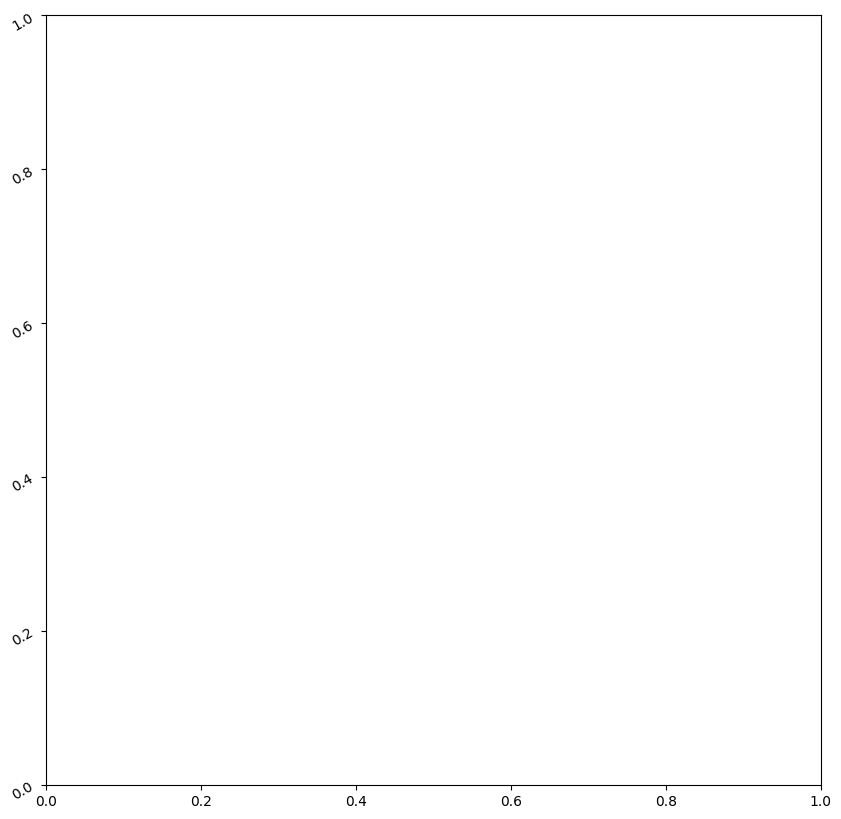

In [8]:
data = raster_transpose
T = data.shape[1]

# Sum the spikes for each neuron and divide by the time window T to get the firing rate
firing_rates = spike_trains.count(0)/(T*time_step)

# 2. Calculate the average firing rate across all neurons
# Calculate the average firing rate
average_firing_rate = np.mean(firing_rates)

temp = pd.DataFrame(firing_rates, columns=['Firing Rate']).sort_values('Firing Rate')
temp = temp[temp['Firing Rate'].round(1)!=0]

plt.figure(figsize=(10,10))
sns.barplot(x='Firing Rate', y=temp.index, data=temp, orient='h',)
plt.yticks(rotation=30)


print("Firing Rates for each neuron:\n", firing_rates)
print('\n')
print("Average Firing Rate across all neurons:\n", average_firing_rate)



### **Burst Rate Analysis**:

Average Burst Rate across (Bursts/Minute) all neurons:
 0.0


Average Burst Duration (ms) across all neurons:
 nan


Percentage of Bursting Channels:
 0.0


Average % of Spikes In Burst:
 0.0


Average Interburst Interval (s):
 0.0


Average Firing Rate across all neurons:
 0.0038590751072260137




Text(0.5, 1.0, '% Spikes in Bursts')

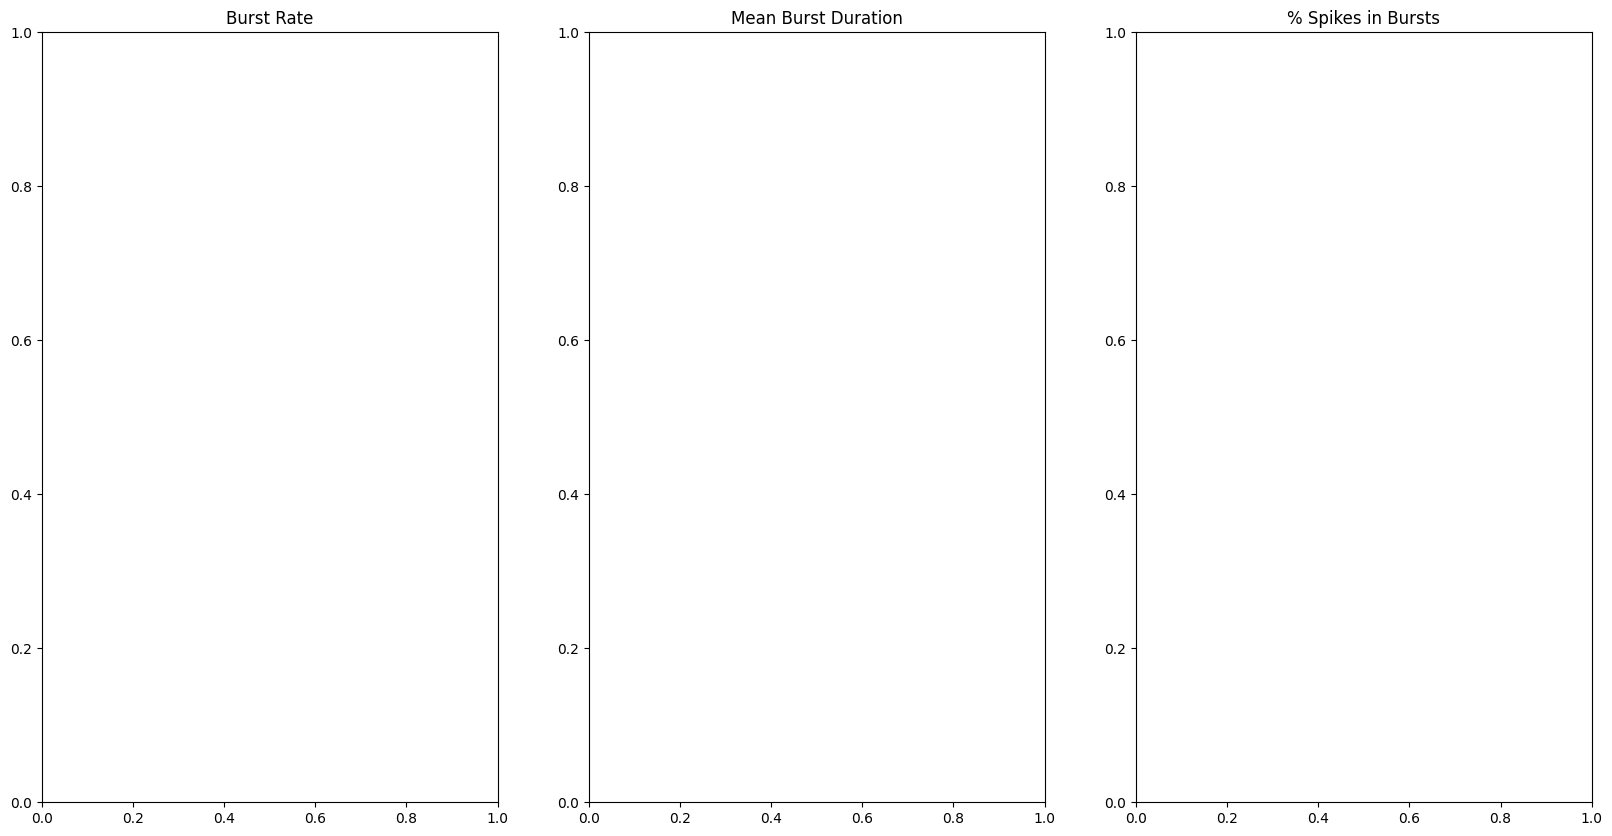

In [9]:
burst_agg = pd.read_csv(burst_file_prefix+'_Bursts_Aggregated.txt', skiprows=6, engine='python', sep='\t').drop([0])
burst_agg['Burst Rate'] = burst_agg['Number Of Bursts']*60/(T*time_step)

# print("Burst Rates for each neuron:\n", burst_agg[['Channel', 'Burst Rate']])
# print('\n')
print("Average Burst Rate across (Bursts/Minute) all neurons:\n", burst_agg['Burst Rate'].mean())
print('\n')
print("Average Burst Duration (ms) across all neurons:\n", burst_agg['Mean Burst Duration'].astype(float).mean())
print('\n')
print("Percentage of Bursting Channels:\n", burst_agg['Number Of Bursts'].fillna(0).astype(bool).sum(axis=0)/len(burst_agg['Number Of Bursts'])*100)
print('\n')
print("Average % of Spikes In Burst:\n", burst_agg['% Spikes in Bursts'].fillna(0).astype(float).mean())
print('\n')
print("Average Interburst Interval (s):\n", burst_agg['Mean Interburst Interval'].fillna(0).astype(float).mean()*time_step)
print('\n')
print("Average Firing Rate across all neurons:\n", average_firing_rate)
print('\n')
fig, axs = plt.subplots(1, 3, figsize=(20, 10))

temp = burst_agg.sort_values('Burst Rate')
temp = temp[temp['Burst Rate']!=0]
sns.barplot(x='Burst Rate', y="Channel", data=temp, orient='h', ax=axs[0])
axs[0].set_title('Burst Rate')


temp = burst_agg.astype(float).sort_values('Mean Burst Duration')
temp =  temp[~temp['Burst Rate'].isin([0, np.nan, 'Nan'])]
sns.barplot(x='Mean Burst Duration', y="Channel", data=temp, orient='h', ax=axs[1])
axs[1].set_title('Mean Burst Duration')


temp = burst_agg.fillna(0).astype(float).sort_values('% Spikes in Bursts')
temp =  temp[~temp['% Spikes in Bursts'].isin([0, np.nan, 'Nan'])]
sns.barplot(x='% Spikes in Bursts', y="Channel", data=temp, orient='h', ax=axs[2])
axs[2].set_title('% Spikes in Bursts')



Average Burst Rate across (Bursts/Minute) all neurons:
 0.0


Average Burst Duration (ms) across all neurons:
 nan


Percentage of Bursting Channels:
 0.0


Average % of Spikes In Burst:
 0.0


Average Interburst Interval (s):
 0.0


Average Firing Rate across all neurons:
 0.0038590751072260137




Text(0.5, 1.0, '% Spikes in Bursts')

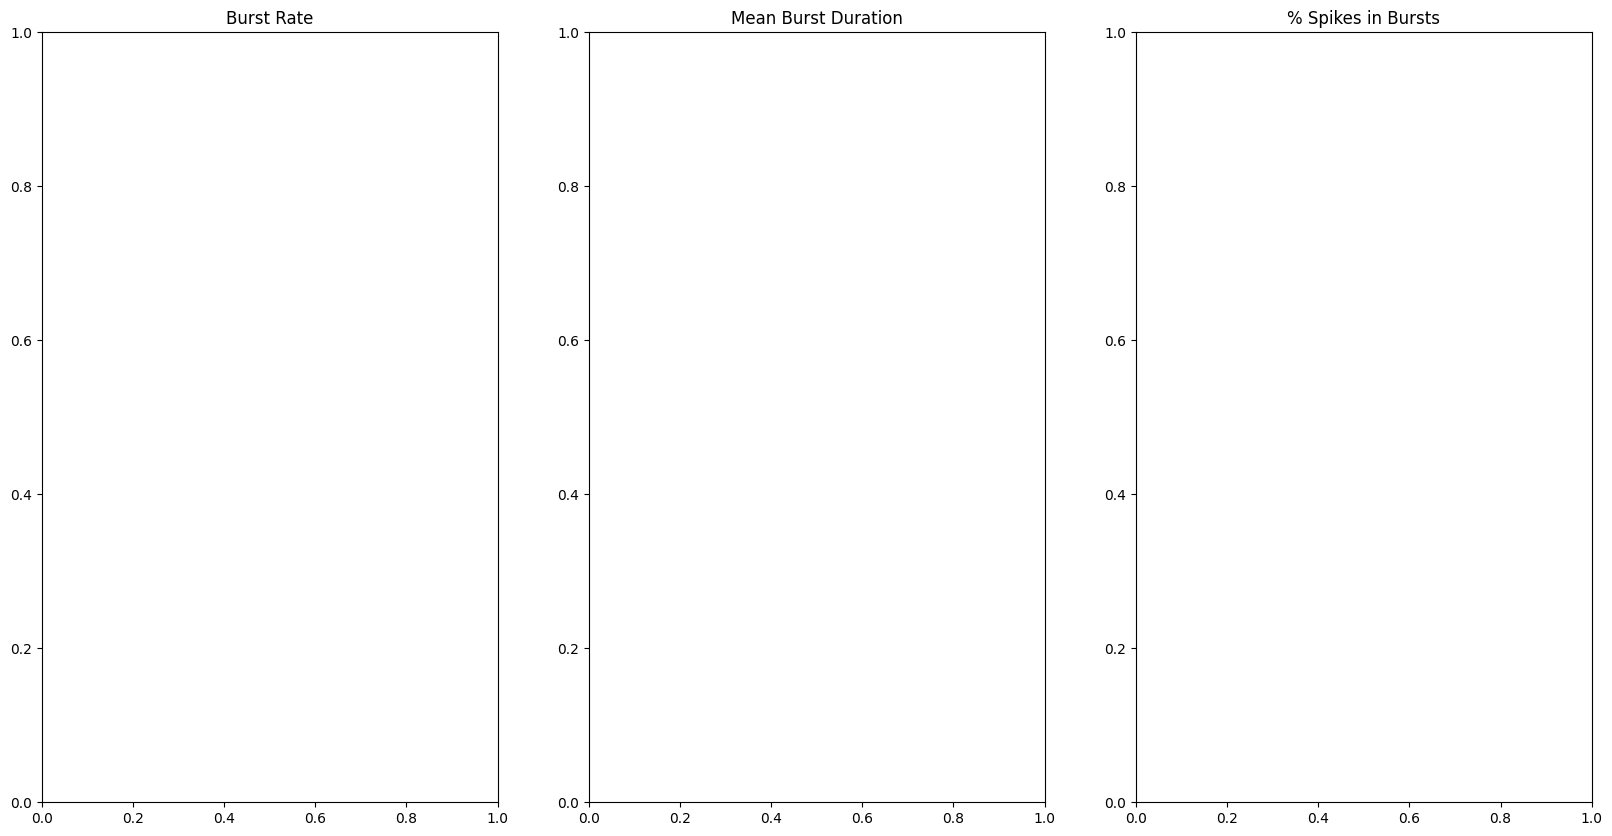

In [10]:
burst_agg = pd.read_csv(burst_file_prefix+'_Bursts_Aggregated.txt', skiprows=6, engine='python', sep='\t').drop([0])
burst_agg['Burst Rate'] = burst_agg['Number Of Bursts']*60/(T*time_step)

# print("Burst Rates for each neuron:\n", burst_agg[['Channel', 'Burst Rate']])
# print('\n')
print("Average Burst Rate across (Bursts/Minute) all neurons:\n", burst_agg['Burst Rate'].mean())
print('\n')
print("Average Burst Duration (ms) across all neurons:\n", burst_agg['Mean Burst Duration'].astype(float).mean())
print('\n')
print("Percentage of Bursting Channels:\n", burst_agg['Number Of Bursts'].fillna(0).astype(bool).sum(axis=0)/len(burst_agg['Number Of Bursts'])*100)
print('\n')
print("Average % of Spikes In Burst:\n", burst_agg['% Spikes in Bursts'].fillna(0).astype(float).mean())
print('\n')
print("Average Interburst Interval (s):\n", burst_agg['Mean Interburst Interval'].fillna(0).astype(float).mean()*time_step)
print('\n')
print("Average Firing Rate across all neurons:\n", average_firing_rate)
print('\n')
fig, axs = plt.subplots(1, 3, figsize=(20, 10))

temp = burst_agg.sort_values('Burst Rate')
temp = temp[temp['Burst Rate']!=0]
sns.barplot(x='Burst Rate', y="Channel", data=temp, orient='h', ax=axs[0])
axs[0].set_title('Burst Rate')


temp = burst_agg.astype(float).sort_values('Mean Burst Duration')
temp =  temp[~temp['Burst Rate'].isin([0, np.nan, 'Nan'])]
sns.barplot(x='Mean Burst Duration', y="Channel", data=temp, orient='h', ax=axs[1])
axs[1].set_title('Mean Burst Duration')


temp = burst_agg.fillna(0).astype(float).sort_values('% Spikes in Bursts')
temp =  temp[~temp['% Spikes in Bursts'].isin([0, np.nan, 'Nan'])]
sns.barplot(x='% Spikes in Bursts', y="Channel", data=temp, orient='h', ax=axs[2])
axs[2].set_title('% Spikes in Bursts')



### **Spike Synchrony Analysis**:

Assess the degree of synchrony in spiking activity across neurons. This can be done by calculating pairwise correlations in spike timing or by using metrics like the population vector or the spike-time tiling coefficient.

To assess the degree of synchrony in spiking activity across neurons:

1. #### **Pairwise Correlation Method**:

   - **Definition**: Measures how the spiking of one neuron is correlated with that of another.

   - **Mathematical Formulation**:
   - For two neurons $(i)$ and $( j )$, their correlation coefficient $( C_{ij} )$ over a time window $( T )$ is given by:
   
   # $[ C_{ij} = \frac{\sum_{t=1}^{T}(S_i(t) - \bar{S}_i)(S_j(t) - \bar{S}_j)}{\sqrt{\sum_{t=1}^{T}(S_i(t) - \bar{S}_i)^2}\sqrt{\sum_{t=1}^{T}(S_j(t) - \bar{S}_j)^2}} ]$
   
   - Where $(\bar{S}_i )$ and $(\bar{S}_j )$ are the average spike rates of neurons $( i )$ and $( j )$, respectively, over $( T )$.

2. #### **Population Vector Analysis** (for a holistic view):

   - **Definition**: Represents the collective activity of the neuron population at each time point.
   
   - **Mathematical Formulation**:
     - Construct a vector $( \mathbf{P}(t) )$ at each time $(t)$ whose elements are the spike trains of each neuron at that time.
     - The population vector at time $( t )$ is:
       # $[\mathbf{P}(t) = [S_1(t), S_2(t), ..., S_N(t)] ]$
     - The degree of synchrony at time $( t )$ can be quantified by the norm of $( \mathbf{P}(t) )$ or other statistical measures.


These methods provide insights into the collective behavior of neuronal networks, reflecting aspects like average activity level and temporal coordination among neurons.

In [11]:
# Define your time window T (in terms of the number of timepoints)
T = 10000000 # Replace with your actual time window length

# Check if the time window exceeds the length of the data
if T > data.shape[1]:
    raise ValueError("Time window T exceeds the data length.")

#data_truncated = data[:, :T] if data.shape[1] >= T else np.pad(data, ((0, 0), (0, T - data.shape[1])), mode='constant')
data_truncated = data[:, :T]

# Pairwise Correlation Method
# Calculate the pairwise correlation matrix
correlation_matrix = np.corrcoef(data_truncated)

# Population Vector Analysis
# Calculate the population vector for each time point
population_vectors = data_truncated.T  # Transpose to make each row a time point

population_vector_norms = np.linalg.norm(population_vectors, axis=1)

# Output the results
print("Pairwise Correlation Matrix:\n", correlation_matrix)
print("Norms of Population Vectors:", population_vector_norms)


c:\Users\Angele Parent\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Angele Parent\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Pairwise Correlation Matrix:
 [[1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 ...
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]
 [1. 1. 1. ... 1. 1. 1.]]
Norms of Population Vectors: [7.54983444 0.         0.         ... 0.         0.         0.        ]


In [12]:
# # Generate a mask for the upper triangle
# mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# # Set up the matplotlib figure
# f, ax = plt.subplots(figsize=(10, 10))

# # Generate a custom diverging colormap
# cmap = sns.diverging_palette(230, 20, as_cmap=True)

# # Draw the heatmap with the mask and correct aspect ratio
# sns.heatmap(correlation_matrix,
#             mask=mask,
#             cmap=cmap,
#             vmin=-1,
#             vmax=1,
#             center=0,
#             square=True, linewidths=0, cbar_kws={"shrink": .5})
# plt.show()

# # Set up the matplotlib figure
# f, ax = plt.subplots(figsize=(10, 10))
# # Generate a custom diverging colormap
# sns.heatmap(correlation_matrix,
#             #mask=mask,
#             cmap=cmap,
#             vmin=-1,
#             vmax=1,
#             center=0,
#             square=True, linewidths=0, cbar_kws={"shrink": .5})

# plt.show()

# **Correlation Index**:
## Analysis of correlation index

The correlation index $(i_{A,B})$ between two spike trains A and B is defined as the factor by which the firing rate of neuron A increases over its mean value if measured within a fixed window (typically 0.05–0.10s) of spikes from neuron B ([Wong et al., 1993](https://pubmed.ncbi.nlm.nih.gov/10202531/)). The following notation is used throughout: the vectors a and b represent the spike times of neurons A and B; $(a_{i})$ is the i'th spike in train A and $( b_{j})$ is the j'th spike in train B. The correlation index is given by the following:

# $i_{A,B} = \frac{N_{A,B[-\Delta t, \Delta t]} \cdot T}{N_A \cdot N_B \cdot 2\Delta t}$

where $N_{A} = |a|$ (total number of spikes of A in recording), $N_{B}=|b|$, $T = $ length of recording, $ \Delta t =$ synchronicity window, and $N_{A,B[-\Delta t, \Delta t]}$ is the number of spike pairs where a spike from train A falls within $(\pm \Delta t)$ of a spike from train B as follows:

# $ N_{A,B[-\Delta t, \Delta t]} = \sum_{i=1}^{N_A} \sum_{j=1}^{N_B} 1_{\Delta t}(|a_i - b_j|)$

where

# $
1_{\Delta t}(x) =
\begin{cases}
1 & \text{if } |x| \leq \Delta t \\
0 & \text{otherwise}
\end{cases}
$


In [13]:
# #@title Correlation Index Helper Functions

# def correlation_index(spike_times_A, spike_times_B, delta_t, T):
#     """
#     Calculate the correlation index between two spike trains A and B.

#     Parameters:
#     spike_times_A (array-like): Spike times for neuron A.
#     spike_times_B (array-like): Spike times for neuron B.
#     delta_t (float): Synchronicity window size.

#     Returns:
#     float: Correlation index.
#     """
#     N_A = len(spike_times_A)
#     N_B = len(spike_times_B)

#     # Count the number of spike pairs within the synchronicity window delta_t
#     N_AB = sum(1 for a in spike_times_A for b in spike_times_B if abs(a - b) <= delta_t)

#     # Calculate the correlation index using the formula provided
#     i_AB = N_AB  * T / (N_A * N_B * 2 * delta_t)
#     return i_AB

# def compute_correlation_matrix(spike_df, delta_t, T):
#     """
#     Compute the correlation index for each pair of neurons in a dataframe.

#     Parameters:
#     spike_df (DataFrame): DataFrame where each column represents a neuron and contains spike times.
#     delta_t (float): Synchronicity window size.

#     Returns:
#     DataFrame: Correlation index matrix for all pairs of neurons.
#     """
#     # Number of neurons
#     num_neurons = spike_df.shape[1]
#     # Initialize an empty correlation matrix
#     correlation_matrix = np.zeros((num_neurons, num_neurons))

#     # Iterate over each pair of neurons and calculate the correlation index
#     for i in range(num_neurons):
#         for j in range(i, num_neurons):  # Only need to calculate for one triangle
#             if i != j:
#               #     # Extract spike times for neurons i and j
#               spike_times_i = spike_df.iloc[:, i].dropna().values
#               spike_times_j = spike_df.iloc[:, j].dropna().values
#               # Calculate the correlation index
#               correlation_matrix[i, j] = correlation_index(spike_times_i, spike_times_j, delta_t, T)
#               correlation_matrix[j, i] = correlation_matrix[i, j]  # Symmetric matrix
#             else:
#                 # The diagonal is the autocorrelation, which is not defined in the same way
#                 # so we set it to NaN or some other indicative value
#                 correlation_matrix[i, j] = np.nan

#     # Convert to DataFrame for better readability
#     correlation_df = pd.DataFrame(correlation_matrix, index=spike_df.columns, columns=spike_df.columns)
#     return correlation_df


In [14]:
def correlation_index(spike_times_A, spike_times_B, delta_t, T):
    """
    Calculate the correlation index between two spike trains A and B.
    
    Parameters:
    spike_times_A (array-like): Spike times for neuron A.
    spike_times_B (array-like): Spike times for neuron B.
    delta_t (float): Synchronicity window size.
    T (float): Total recording time.
    
    Returns:
    float: Correlation index.
    """
    # Convert to numpy arrays if not already
    spike_times_A = np.asarray(spike_times_A)
    spike_times_B = np.asarray(spike_times_B)
    
    N_A = len(spike_times_A)
    N_B = len(spike_times_B)
    
    # Handle edge cases
    if N_A == 0 or N_B == 0:
        return 0.0
    
    # Vectorized calculation of time differences
    # Reshape arrays to enable broadcasting
    time_diff = np.abs(spike_times_A[:, np.newaxis] - spike_times_B[np.newaxis, :])
    
    # Count spike pairs within delta_t
    N_AB = np.sum(time_diff <= delta_t)
    
    # Calculate the correlation index
    i_AB = N_AB * T / (N_A * N_B * 2 * delta_t)
    
    return i_AB

def compute_correlation_matrix(spike_df, delta_t, T):
    """
    Compute the correlation index for each pair of neurons in a dataframe.
    
    Parameters:
    spike_df (DataFrame): DataFrame where each column represents a neuron and contains spike times.
    delta_t (float): Synchronicity window size.
    T (float): Total recording time.
    
    Returns:
    DataFrame: Correlation index matrix for all pairs of neurons.
    """
    # Get neuron names
    neurons = spike_df.columns
    num_neurons = len(neurons)
    
    # Pre-extract spike times for all neurons
    spike_times = {neuron: spike_df[neuron].dropna().values for neuron in neurons}
    
    # Initialize correlation matrix
    correlation_matrix = np.zeros((num_neurons, num_neurons))
    
    # Iterate over each pair of neurons and calculate the correlation index
    for i in range(num_neurons):
        # Set diagonal to NaN (autocorrelation not defined)
        correlation_matrix[i, i] = np.nan
        
        # Only calculate for upper triangle (j > i)
        for j in range(i+1, num_neurons):
            # Get spike times for neurons i and j
            times_i = spike_times[neurons[i]]
            times_j = spike_times[neurons[j]]
            
            # Calculate correlation index
            corr_idx = correlation_index(times_i, times_j, delta_t, T)
            
            # Store value in both positions (symmetric matrix)
            correlation_matrix[i, j] = corr_idx
            correlation_matrix[j, i] = corr_idx
    
    # Convert to DataFrame with neuron names as indices and columns
    correlation_df = pd.DataFrame(correlation_matrix, index=neurons, columns=neurons)
    
    return correlation_df

In [15]:
data = spike_trains
spike_df = pd.DataFrame(data)
T = total_obs_time

# Calculate the correlation matrix
correlation_matrix_df = compute_correlation_matrix(spike_df, delta_t, T)

<Figure size 1000x1000 with 0 Axes>

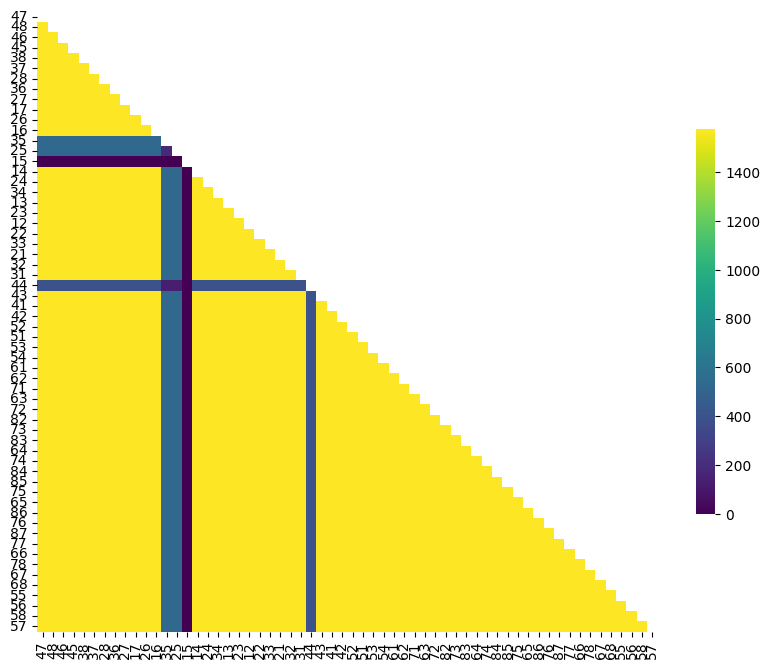

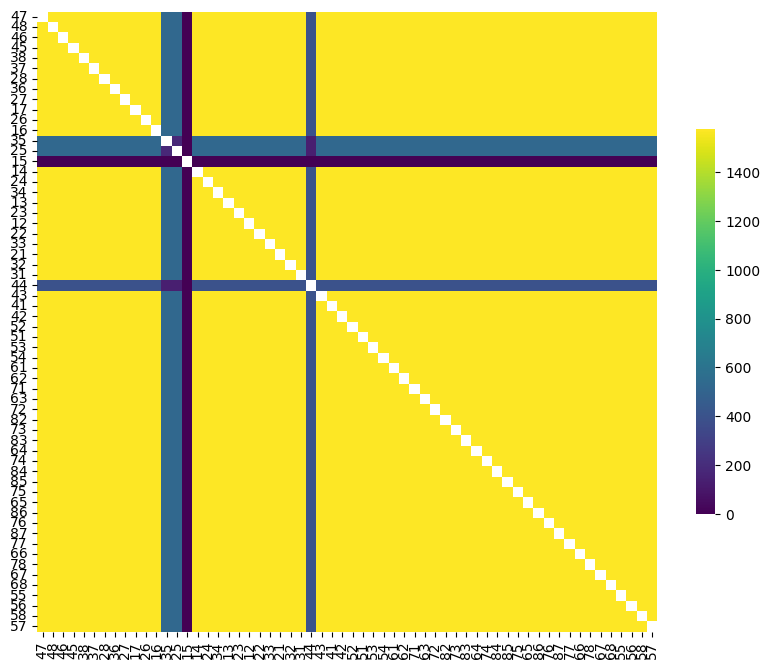

In [16]:
plt.figure(figsize=(10, 10))

# plt.imshow(correlation_matrix_df)
# labels = [i.split('. ')[-1] for i in spike_trains.columns]
# plt.xticks(ticks=list(np.arange(0, correlation_matrix_df.shape[0])), labels=labels)
# plt.yticks(ticks=list(np.arange(0, correlation_matrix_df.shape[0])), labels=labels)
# plt.colorbar()
# plt.show()

mask = np.triu(np.ones_like(correlation_matrix_df, dtype=bool))
f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(correlation_matrix_df,
            mask=mask,
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            cmap='viridis',
            #vmin=correlation_matrix_df.min(),
            #vmax=correlation_matrix_df.max(),
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()



f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(correlation_matrix_df,
            cmap='viridis',
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            #vmin=correlation_matrix_df.min(),
            #vmax=correlation_matrix_df.max(),
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

# **Spike Time Tiling Coefficient**



- $T_{A}$: the proportion of total recording time which lies within ±Δt of any spike from A. $T_{B}$ is calculated similarly.

- $P_{A}$: the proportion of spikes from A which lie within ±Δt of any spike from B. $P_{B}$ calculated similarly.

- The STTC is calculated as:

  # $STTC = ( \frac{1}{2} \left( \frac{P_{A} - T_{B}}{1 - P_{A}T_{B}} + \frac{P_{B} - T_{A}}{1 - P_{B}T_{A}} \right) )$


In [17]:

# #@title Spike Time Tiling Coefficient helper function

# def calculate_STTC(df, delta_t, neuron_a='Neuron A', neuron_b='Neuron B', T=100000):
#     # Extract spike times for neurons A and B
#     spikes_a = df[neuron_a].dropna().values
#     spikes_b = df[neuron_b].dropna().values

#     # Calculate TA and TB
#     # T = max(max(spikes_a), max(spikes_b))  # Total recording time
#     TA = sum([any((spike_b - delta_t) <= spike_a <= (spike_b + delta_t) for spike_b in spikes_b) for spike_a in spikes_a]) * delta_t / T
#     TB = sum([any((spike_a - delta_t) <= spike_b <= (spike_a + delta_t) for spike_a in spikes_a) for spike_b in spikes_b]) * delta_t / T

#     # Calculate PA and PB
#     PA = sum([any((spike_b - delta_t) <= spike_a <= (spike_b + delta_t) for spike_b in spikes_b) for spike_a in spikes_a]) / len(spikes_a)
#     PB = sum([any((spike_a - delta_t) <= spike_b <= (spike_a + delta_t) for spike_a in spikes_a) for spike_b in spikes_b]) / len(spikes_b)

#     # Calculate STTC
#     STTC = 0.5 * ((PA - TB) / (1 - PA * TB) + (PB - TA) / (1 - PB * TA))

#     return STTC

# def calculate_STTC_pairwise(df, delta_t, T):
#     # Initialize an empty dataframe to store STTC values for each neuron pair
#     neurons = df.columns
#     sttc_matrix = pd.DataFrame(index=neurons, columns=neurons, dtype=float)

#     # Calculate STTC for each pair of neurons
#     for neuron_a in neurons:
#         for neuron_b in neurons:
#             if neuron_a != neuron_b:
#                 # Calculate STTC for the pair
#                 sttc_matrix.loc[neuron_a, neuron_b] = calculate_STTC(df, delta_t, neuron_a, neuron_b, T)
#             else:
#                 # STTC is 1 for autocorrelation (neuron with itself)
#                 sttc_matrix.loc[neuron_a, neuron_b] = 1.0

#     return sttc_matrix


In [18]:

def compute_T(spikes, delta_t, T_total):
    spikes = np.sort(spikes)
    covered = 0
    start = max(spikes[0] - delta_t, 0)
    end = min(spikes[0] + delta_t, T_total)
    for spike in spikes[1:]:
        new_start = max(spike - delta_t, 0)
        new_end = min(spike + delta_t, T_total)
        if new_start <= end:
            end = max(end, new_end)
        else:
            covered += end - start
            start = new_start
            end = new_end
    covered += end - start
    return covered / T_total

def calculate_STTC(spikes_a, spikes_b, delta_t, T=100000):
    """
    Calculate Spike Time Tiling Coefficient between two spike trains.
    
    Parameters:
    -----------
    spikes_a : array-like
        Spike times for neuron A
    spikes_b : array-like
        Spike times for neuron B
    delta_t : float
        Time window
    T : float
        Total recording time
        
    Returns:
    --------
    float
        STTC value
    """
    if len(spikes_a) == 0 or len(spikes_b) == 0:
        return 0.0
    
    # Convert to numpy arrays for faster operations
    spikes_a = np.array(spikes_a)
    spikes_b = np.array(spikes_b)
    
    # Create a 2D matrix of time differences
    time_diff = np.abs(spikes_a[:, np.newaxis] - spikes_b[np.newaxis, :])
    
    # Find spikes within delta_t window
    within_window = time_diff <= delta_t
    
    # Calculate PA and PB (proportion of spikes from one train that fall within 
    # delta_t of any spike from the other train)
    Pa = np.sum(np.any(within_window, axis=1)) / len(spikes_a)
    Pb = np.sum(np.any(within_window, axis=0)) / len(spikes_b)
    
    # Calculate TA and TB (proportion of total recording time that falls within 
    # delta_t of any spike from the train)
    Ta = compute_T (spikes_a, delta_t, T)
    #np.sum(np.any(within_window, axis=1)) * delta_t / T
    Tb = compute_T (spikes_b, delta_t, T)
    #= np.sum(np.any(within_window, axis=0)) * delta_t / T
    
    # Calculate STTC
    if Pa == 1 and Tb == 1:
        part1 = 1
    else:
        part1 = (Pa - Tb) / (1 - Pa * Tb)
        
    if Pb == 1 and Ta == 1:
        part2 = 1
    else:
        part2 = (Pb - Ta) / (1 - Pb * Ta)
    
    STTC = 0.5 * (part1 + part2)
    
    return STTC

def calculate_STTC_from_df(df, delta_t, neuron_a='Neuron A', neuron_b='Neuron B', T=100000):
    """Wrapper function to extract spike times from a DataFrame and calculate STTC"""
    spikes_a = df[neuron_a].dropna().values
    spikes_b = df[neuron_b].dropna().values
    return calculate_STTC(spikes_a, spikes_b, delta_t, T)

def calculate_STTC_pairwise(df, delta_t, T):
    """
    Calculate STTC for all pairs of neurons in the DataFrame.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame where each column represents a neuron and contains spike times
    delta_t : float
        Time window
    T : float
        Total recording time
        
    Returns:
    --------
    pandas.DataFrame
        Matrix of STTC values for each neuron pair
    """
    neurons = df.columns
    n_neurons = len(neurons)
    
    # Pre-extract all spike trains to avoid repeated operations
    spike_trains = {neuron: df[neuron].dropna().values for neuron in neurons}
    
    # Initialize the result matrix
    sttc_matrix = pd.DataFrame(index=neurons, columns=neurons, dtype=float)
    
    # Calculate STTC for each pair
    for i, neuron_a in enumerate(neurons):
        # Set diagonal to 1 (neuron with itself)
        sttc_matrix.loc[neuron_a, neuron_a] = 1.0
        
        # Only compute for j > i to avoid redundant calculations
        for j, neuron_b in enumerate(neurons):
            if j > i:  # Only compute upper triangle
                spikes_a = spike_trains[neuron_a]
                spikes_b = spike_trains[neuron_b]
                
                # Calculate STTC for this pair
                sttc_value = calculate_STTC(spikes_a, spikes_b, delta_t, T)
                
                # Store the value in both positions (symmetric matrix)
                sttc_matrix.loc[neuron_a, neuron_b] = sttc_value
                sttc_matrix.loc[neuron_b, neuron_a] = sttc_value
            elif j < i:
                # Copy value from already computed position (lower triangle)
                sttc_matrix.loc[neuron_a, neuron_b] = sttc_matrix.loc[neuron_b, neuron_a]
    
    return sttc_matrix

In [19]:
df = pd.DataFrame(spike_trains)
delta_t = 50000 # 50 or 100 ms as a typical value
T = total_obs_time

# Calculate the STTC matrix for all neuron pairs
sttc_matrix = calculate_STTC_pairwise(df, delta_t, T)


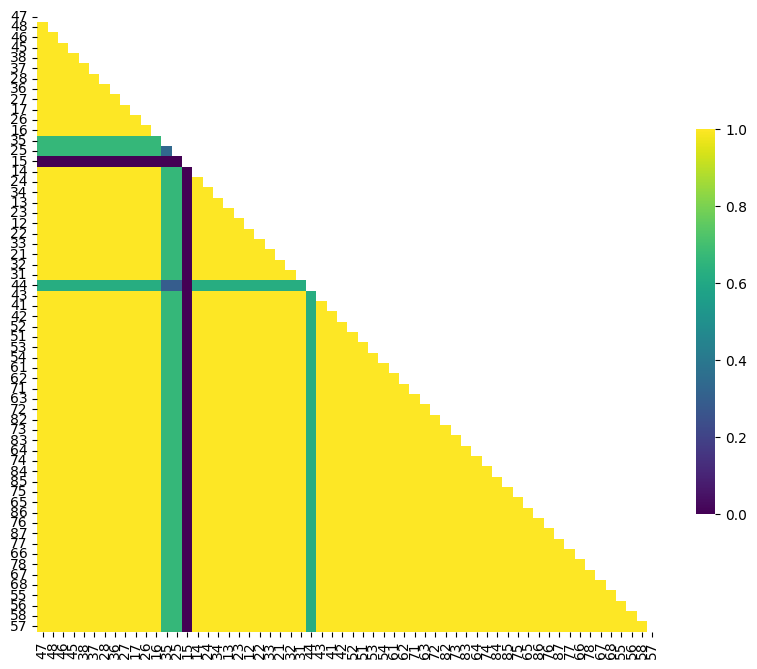

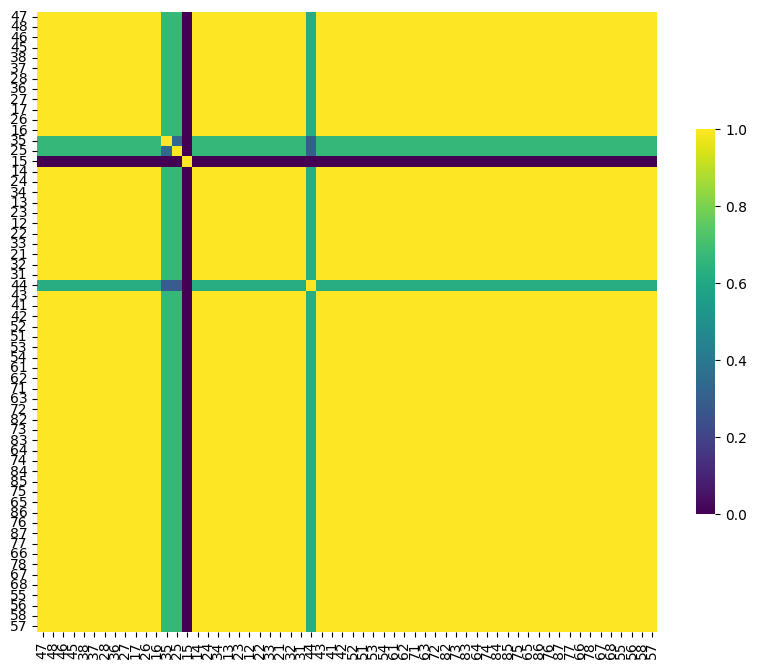

In [20]:
# plt.figure(figsize=(10, 10))
# plt.imshow(sttc_matrix, vmax=1, vmin=0)
# labels = [i.split('. ')[-1] for i in spike_trains.columns]
# plt.xticks(ticks=list(np.arange(0, sttc_matrix.shape[0])), labels=labels)
# plt.yticks(ticks=list(np.arange(0, sttc_matrix.shape[0])), labels=labels)
# plt.colorbar()
# plt.show()


mask = np.triu(np.ones_like(sttc_matrix, dtype=bool))
f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(sttc_matrix,
            mask=mask,
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            cmap='viridis',
            vmin=0,
            vmax=1,
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()



f, ax = plt.subplots(figsize=(10, 10))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(sttc_matrix,
            xticklabels=spike_trains.columns,
            yticklabels=spike_trains.columns,
            cmap='viridis',
            vmin=0,
            vmax=1,
            square=True, linewidths=0, cbar_kws={"shrink": .5})
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

In [21]:

#from scipy.io import loadmat                 # To load .mat files
#from pylab import *                          # Import plotting functions

#data = spike_trains                          # Load the data,
#E1 = data['1']                               # ... from the first electrode,
#E2 = data['11']                              # ... and from the second electrode.
#dt = 1000000                                 # ... to get the sampling interval,
#T = total_obs_time                                    # ... and the total time of the recording.
#N = E1.shape[0]                              # Determine the number of sample points per trial
#scale = 2 * dt**2 / T                        # Scaling constant

# Compute the Fourier transform for each trial

#xf = array([rfft(x - x.mean()) for x in E1])  # ... in E1
#yf = array([rfft(y - y.mean()) for y in E2])  # ... and in E2

# Compute the spectra
#Sxx = scale * (xf * xf.conj())                # Spectrum of E1 trials
#Syy = scale * (yf * yf.conj())                # ... and E2 trials
#Sxy = scale * (xf * yf.conj())                # ... and the cross spectrum

#f = rfftfreq(N, dt)                           # Define the frequency axis

# Plot the average spectrum over trials in decibels vs frequency
#plot(f, 10 * log10(Sxx.mean(0).real), lw=3, label='Trial-averaged spectrum')
# ... and the spectrum from the first trial for reference
# plt.plot(f, 10 * np.log10(Sxx[0].real), 'k', label='Single-trial spectrum')

#xlim([0, 100])                                # ... in select frequency range,
#ylim([-50, 0])                                # ... in select power range,
#xlabel('Frequency [Hz]')                      # ... with axes labelled.
#ylabel('Power [ mV^2/Hz]')
#title('Trial-averaged spectrum')
#legend()
#savefig('imgs/trial_avg_spectrum')
#show()

In [22]:
#time_series_df = pd.DataFrame(raster_transpose)

In [23]:
#from scipy.fft import fft


# Compute the power spectrum for each neuron
#import numpy as np

#def calculate_power_spectrum(series):
    # Check if the series is not empty
    #if len(series) > 0:
        # Compute FFT and return power spectrum
       # return np.abs(np.fft.fft(series)) ** 2
    #else:
        # If series is empty, return empty array
        #return np.array([])

# Apply the function to each element of the DataFrame
#df = time_series_df.iloc[:, 0:1000000]
#power_spectra = df.apply(lambda series: calculate_power_spectrum(series))


In [24]:
#import pandas as pd
#import numpy as np
#from scipy.signal import welch


#dt = time_step  # Time step in seconds
##fs = 1  # Sampling frequency

# time_series_df = pd.DataFrame(raster_transpose)
# Function to compute Welch's periodogram for a time series
#def compute_welch(series, fs):
    #frequencies, power = welch(series, fs=fs,)
    #return frequencies, power

# Compute Welch's periodogram for each neuron
#welch_results = df.apply(lambda series: compute_welch(series, fs))


In [25]:
#import numpy as np
#from scipy import signal
#import matplotlib.pyplot as plt
#rng = np.random.default_rng()

#fs = 10e3
#N = 1e5

#amp = 2*np.sqrt(2)
#freq = 1234.0
#noise_power = 0.001 * fs / 2
#time = np.arange(N) / fs
#x = amp*np.sin(2*np.pi*freq*time)
#x += rng.normal(scale=np.sqrt(noise_power), size=time.shape)

In [26]:
#x.shape

In [27]:
#welch_results[0]

In [28]:
#plt.plot(welch_results[0][0], welch_results[1][0])